<div dir='rtl' lang='ar'>
    مقدمه :
    
    
    توی این فایل قراره به داده های مشتریان یک بانک نگاهی بی اندازیم و به دسته های مناسب تقسیم بندیشون کنیم
    جهت بررسی بهترین خوشه بندی در انتها، خوشه بندی های مختلف رو روی نمودار اوردیم تا از لحاظ بصری هم مقایسه صورت بگیره
</div>

اضافه کردن کتابخانه های مورد نیاز اولیه

In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('Dataset.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


نگاهی کلی به دیتاها، تغییر و پیش پردازش در صورت نیاز

In [4]:
print(f'data shape is : {df.shape}')
print(df.dtypes)

data shape is : (200, 5)
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


In [5]:
df['Gender'] = df['Gender'].map({
    'Male': 0,
    'Female': 1
})
df.dtypes

CustomerID                int64
Gender                    int64
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

ایجاد آرایه نامپای برای مراحل نرمال سازی

In [6]:
dataset = np.asanyarray(df[['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']])
dataset[: 5]

array([[ 0, 19, 15, 39],
       [ 0, 21, 15, 81],
       [ 1, 20, 16,  6],
       [ 1, 23, 16, 77],
       [ 1, 31, 17, 40]])

نرمال سازی داده ها

In [7]:
from sklearn.preprocessing import StandardScaler

normalizer = StandardScaler()
X = normalizer.fit_transform(dataset)
X[: 5]

array([[-1.12815215, -1.42456879, -1.73899919, -0.43480148],
       [-1.12815215, -1.28103541, -1.73899919,  1.19570407],
       [ 0.88640526, -1.3528021 , -1.70082976, -1.71591298],
       [ 0.88640526, -1.13750203, -1.70082976,  1.04041783],
       [ 0.88640526, -0.56336851, -1.66266033, -0.39597992]])

<div dir="rtl">
ساخت مدل با n های مختلف و به تصویر کشیدن نتیجه هر n
</div>

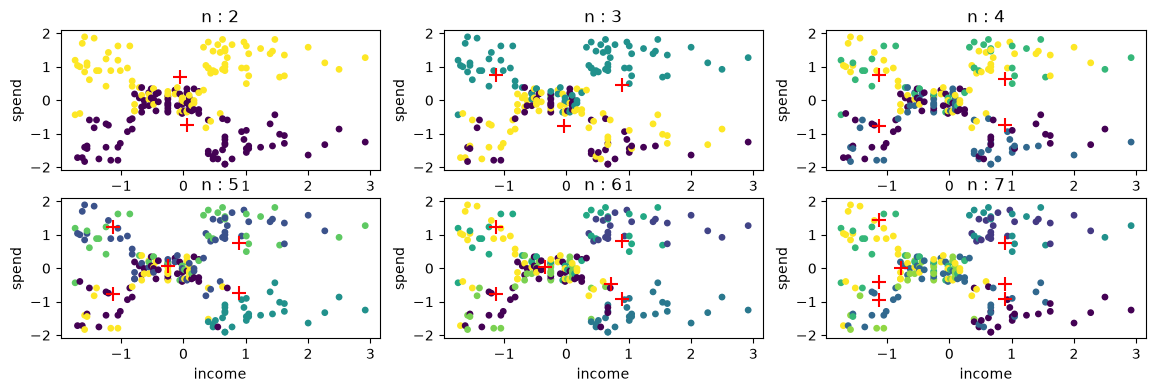

In [75]:
from sklearn.cluster import KMeans
import matplotlib.pylab as plt

fig, axs = plt.subplots(figsize=(14, 4), ncols=3, nrows=2)

counter = 2
for i, plot in enumerate(axs.flat, start=1):
    model = KMeans(n_clusters=i + 1, init='k-means++', n_init=12)
    model.fit(X)

    plot.set_title(f'n : {i + 1}')
    plot.set_xlabel('income')
    plot.set_ylabel('spend')
    plot.scatter(
        X[:, 2], 
        X[:, 3],
        c=model.labels_,
        s=15
    )
    plot.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    c='red',
    marker='+',
    s=100
)

<div dir='rtl'>
    نتیجه گیری :
    گویا بهترین خوشه بندی با n = 2 صورت میگیره

    اما وسط نمودار تراکمی رو مشاهده می کنیم که الگوریتم K-mean به خوبی نتونسته تفکیک بده
    توی فایل های بعدی میریم با الگوریتم hierarchical و DBSCAN خوشه بندی انجام بدیم
    نظری که خودم دارم با توجه به تراکم موجود شاید DBSCAN بهترین نتیجه رو بده
    پس بریم ببینیم ...
</div>